In [8]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from utils import wasserstein

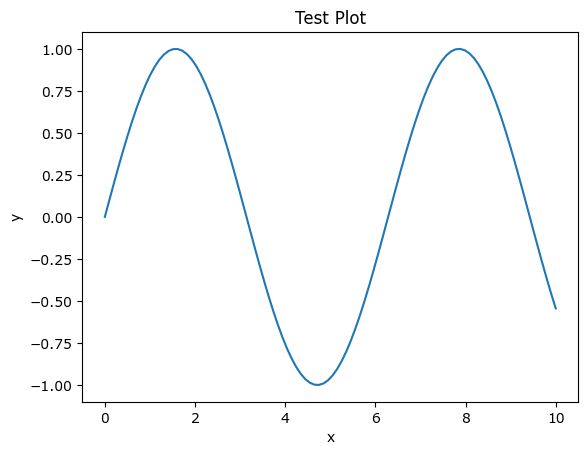

In [ ]:
def test():
    x = np.linspace(0, 10, 100)
    y = np.sin(x)
    plt.plot(x, y)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Test Plot')
    plt.show()
test()

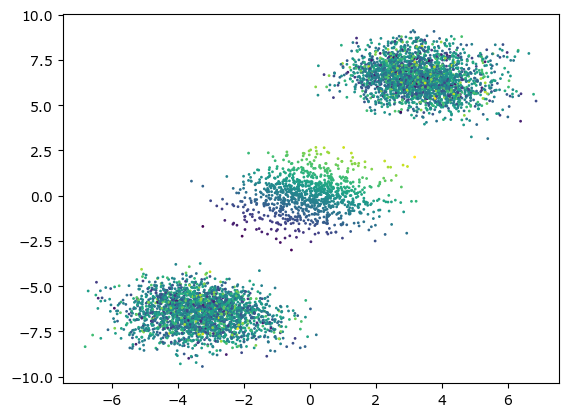

In [ ]:
import random
seed = 3407
np.random.seed(seed)
random.seed(seed)
n_samples = 1000
batch_size = 1000
t = 1
nu = 0.3
mix= 2
dim = 2
x = np.random.randn(n_samples, dim)
x_labels = np.arange(1000)
dot = np.dot(x, [1, 2])
dot
y = []
for _ in range(5):
      sg = np.sign(dot + mix * np.random.randn(n_samples,))
      v = np.repeat([[3, 6]], repeats=1000, axis=0)
      y_tmp = x + sg.reshape(-1, 1) * v + np.sqrt(t) * nu * np.random.randn(n_samples, dim)
      y.append(y_tmp)
y = np.concatenate(y, axis=0)
y_labels = np.concatenate([x_labels] * 5, axis=0)
plt.scatter(x[:,0], x[:,1], c=dot, s=1)
plt.scatter(y[:,0], y[:,1], c=np.repeat(dot, repeats=5, axis=0), s=1)


In [11]:
y_label_dic = {}
for i in range(len(y_labels)):
    if y_labels[i] not in y_label_dic:
        y_label_dic[y_labels[i]] = []
    y_label_dic[y_labels[i]].append(i)

y_label_dic

{0: [0, 1000, 2000, 3000, 4000],
 1: [1, 1001, 2001, 3001, 4001],
 2: [2, 1002, 2002, 3002, 4002],
 3: [3, 1003, 2003, 3003, 4003],
 4: [4, 1004, 2004, 3004, 4004],
 5: [5, 1005, 2005, 3005, 4005],
 6: [6, 1006, 2006, 3006, 4006],
 7: [7, 1007, 2007, 3007, 4007],
 8: [8, 1008, 2008, 3008, 4008],
 9: [9, 1009, 2009, 3009, 4009],
 10: [10, 1010, 2010, 3010, 4010],
 11: [11, 1011, 2011, 3011, 4011],
 12: [12, 1012, 2012, 3012, 4012],
 13: [13, 1013, 2013, 3013, 4013],
 14: [14, 1014, 2014, 3014, 4014],
 15: [15, 1015, 2015, 3015, 4015],
 16: [16, 1016, 2016, 3016, 4016],
 17: [17, 1017, 2017, 3017, 4017],
 18: [18, 1018, 2018, 3018, 4018],
 19: [19, 1019, 2019, 3019, 4019],
 20: [20, 1020, 2020, 3020, 4020],
 21: [21, 1021, 2021, 3021, 4021],
 22: [22, 1022, 2022, 3022, 4022],
 23: [23, 1023, 2023, 3023, 4023],
 24: [24, 1024, 2024, 3024, 4024],
 25: [25, 1025, 2025, 3025, 4025],
 26: [26, 1026, 2026, 3026, 4026],
 27: [27, 1027, 2027, 3027, 4027],
 28: [28, 1028, 2028, 3028, 4028],
 29: 

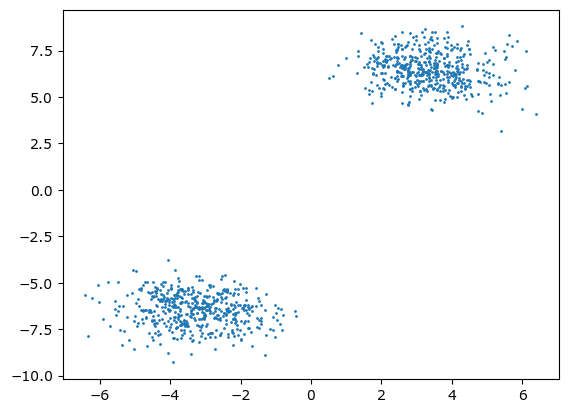

In [12]:
def sample(x_labels, y_label_dic, y):
    idx = [random.choice(y_label_dic[i]) for i in x_labels]
    return np.take(y, idx, axis=0)
sam_y = sample(x_labels, y_label_dic, y)
plt.scatter(sam_y[:,0], sam_y[:,1], s=1)

In [13]:
import torch
import torch.nn as nn

class MeanFlow(nn.Module):
    def __init__(self, dim, decoder_dims):
        super(MeanFlow, self).__init__()
        self.dim = dim
        self.decoder_dims = decoder_dims

        decoder_blocks = [nn.Linear(dim + 2, decoder_dims[0]), nn.ReLU()]
        for i in range(len(decoder_dims)-1):
            decoder_blocks.append(nn.Linear(decoder_dims[i], decoder_dims[i+1]))
            decoder_blocks.append(nn.ReLU())
        decoder_blocks.append(nn.Linear(decoder_dims[-1], dim))
        self.decoder_net = nn.Sequential(*decoder_blocks)

    def forward(self, x, r, t):
        ipt = torch.cat([x, r.view(-1, 1), t.view(-1, 1)], dim=1)
        return self.decoder_net(ipt)
    
    def loss(self, x, r, t, y):
        
        start = r * y + (1-r) * x
        end = t * y + (1-t) * x
        v = y - x
        ipt = torch.cat([start, r.view(-1, 1), t.view(-1, 1)], dim=1)
        tangent = torch.cat([v, torch.ones_like(r), torch.ones_like(t)], dim=1)
        u, jvp = torch.func.jvp(self.decoder_net, (ipt, ), (tangent, ))
        jvp = jvp.detach()
        v_loss = torch.mean((u - v - (t-r) * jvp)**2)
        return {
            'v_loss': v_loss,

        }
    
    def simulation(self, x, r=0, t=1):
        batch, dim = x.shape
        r = torch.ones((batch, 1)) * r
        t = torch.ones((batch, 1)) * t
        return x + self.decoder_net(torch.cat([x, r, t], dim=1)) * (t-r)


In [ ]:
torch.manual_seed(seed)
toy_model = MeanFlow(dim, [32, 64, 32])
x = torch.tensor(x, dtype=torch.float32)
optimizer = torch.optim.Adam(toy_model.parameters(), lr=1e-3)
for step in range(3000):
    yy = torch.tensor(sample(x_labels, y_label_dic, y), dtype=torch.float32)
    tt = torch.rand((batch_size, 1))
    rr = torch.rand((batch_size, 1))
    r = torch.minimum(tt, rr)
    t = torch.maximum(tt, rr)
    optimizer.zero_grad()
    loss = toy_model.loss(x, r, t, yy)
    if step % 100 == 0:
        print(loss)
    loss = 1 * loss['v_loss'] 
    loss.backward()
    optimizer.step()

{'v_loss': tensor(22.6907, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(53.9609, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(175.8123, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(214.6601, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(263.3653, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(299.2066, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(218.2547, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(288.5537, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(223.5776, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(490.3614, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(421.5213, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(656.8844, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(546.3137, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(889.1721, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(323.9897, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(499.3891, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(377.0145, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(689.9542, grad_fn=<MeanBackward0>)}
{'v_loss': tensor(231.5645, gr

([0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0],
 [0.06680720126885807,
  0.08850799143740196,
  0.11506967022170828,
  0.14685905637589597,
  0.18406012534675953,
  0.2266273523768682,
  0.27425311775007355,
  0.32635522028791997,
  0.3820885778110474,
  0.4403823076297575,
  0.5,
  0.5596176923702426,
  0.6179114221889526,
  0.67364477971208,
  0.7257468822499265,
  0.7733726476231317,
  0.8159398746532405,
  0.853140943624104,
  0.8849303297782918,
  0.9114920085625979,
  0.9331927987311419],
 5.002021241012581)

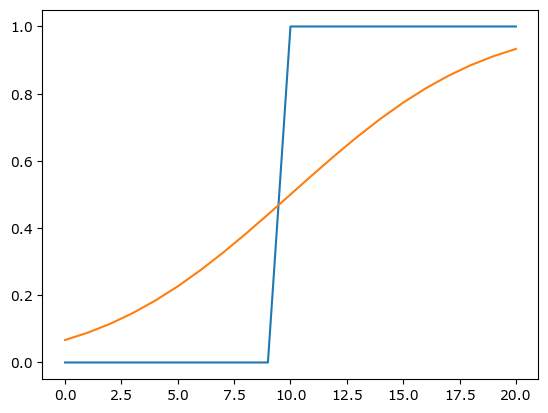

In [51]:
from scipy.stats import norm

lis = []; stand = []
for k in range(21):
    t = -1 + k / 10
    yyy = toy_model.simulation(t*torch.ones((batch_size, dim))).detach()

    prob = norm.sf(-t * 3 / mix)
    yyy.numpy()
    ans = (np.sign(yyy.numpy().dot([1,2])).sum() / batch_size)/2 + 0.5
    lis.append(ans)
    stand.append(prob)

plt.plot(lis)
plt.plot(stand)
with open('ans.txt', 'a') as f:
    f.write(str(lis) + '\n')
lis, stand, np.sum(np.abs(np.array(lis) - np.array(stand)))

1.1013857240675462

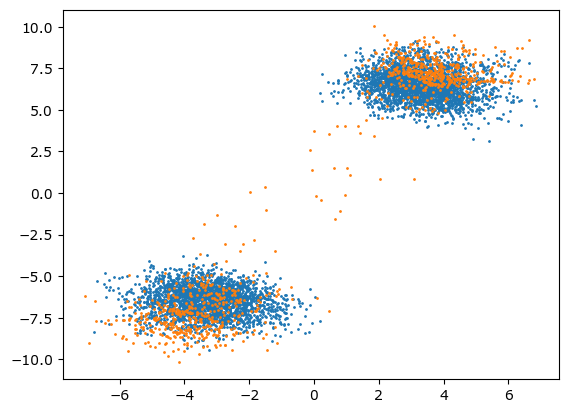

In [18]:
yyy = toy_model.simulation(x).detach()
plt.scatter(y[:,0], y[:,1], s=1)

plt.scatter(yyy[:,0], yyy[:,1], s=1)
wasserstein(yyy, torch.tensor(y, dtype=torch.float32))